<a href="https://colab.research.google.com/github/ShamsirIsmail/Aedes-X-Landing-page/blob/main/notebooks/01_data_collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Clothing Types Image Classification

### SAIA 2113 — Machine Learning Assignment 1

## Phase 1: Dataset Collection and Cleaning



## 1. Project Setup

### 1.1 Google Drive Connection


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive



### 1.2 Project Directory Configuration


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SAIA2113_Clothing_Types_V2"
)

RAW_DIR = PROJECT_ROOT / "raw_dataset"
CLEAN_DIR = PROJECT_ROOT / "cleaned_dataset"
REPORT_DIR = PROJECT_ROOT / "reports"

for folder in [RAW_DIR, CLEAN_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project setup completed!")
print("Project location:", PROJECT_ROOT)


Project setup completed!
Project location: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2



## 2. Dataset Acquisition

### 2.1 Download Original Dataset

Source: Alexey Grigorev — Clothing Dataset (Small)

Repository: https://github.com/alexeygrigorev/clothing-dataset-small

License: CC0-1.0


In [ ]:
from pathlib import Path
import subprocess

DATASET_URL = "https://github.com/alexeygrigorev/clothing-dataset-small.git"

SOURCE_DIR = Path("/content/clothing-dataset-small")

# Download the original dataset
if not SOURCE_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1",
         DATASET_URL, str(SOURCE_DIR)],
        check=True
    )

# Verify download
for split in ["train", "validation", "test"]:
    if not (SOURCE_DIR / split).is_dir():
        raise FileNotFoundError(f"Missing folder: {split}")

print("Dataset downloaded successfully!")
print("Dataset location:", SOURCE_DIR)

# Record dataset version
commit = subprocess.check_output(
    ["git", "-C", str(SOURCE_DIR), "rev-parse", "HEAD"],
    text=True
).strip()

print("Dataset commit:", commit)


Dataset downloaded successfully!
Dataset location: /content/clothing-dataset-small
Dataset commit: 11961516512414bf9f6c150a832cfd21b54a6b54



### 2.2 Dataset Structure and Class Distribution


In [ ]:

import pandas as pd

SPLITS = ["train", "validation", "test"]
IMAGE_FORMATS = {".jpg", ".jpeg", ".png"}

records = []

# Count images in each class and split
for split in SPLITS:
    split_dir = SOURCE_DIR / split

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        count = sum(
            1 for file in class_dir.iterdir()
            if file.is_file()
            and file.suffix.lower() in IMAGE_FORMATS
        )

        records.append({
            "Class": class_dir.name,
            "Split": split,
            "Images": count
        })

# Create dataset summary
source_df = pd.DataFrame(records)

summary = source_df.pivot_table(
    index="Class",
    columns="Split",
    values="Images",
    aggfunc="sum",
    fill_value=0
)

summary = summary.reindex(columns=SPLITS, fill_value=0)
summary["Total"] = summary.sum(axis=1)

display(summary)

print("Total classes:", len(summary))
print("Total images:", summary["Total"].sum())


Split,train,validation,test,Total
Class,,,,
dress,241,32,15,288
hat,123,14,12,149
longsleeve,455,49,72,576
outwear,184,24,38,246
pants,468,49,42,559
shirt,290,29,26,345
shoes,198,26,73,297
shorts,202,25,30,257
skirt,112,12,12,136


Total classes: 10
Total images: 3781



## 3. Class Selection

### 3.1 Extract Selected Clothing Classes

Selected categories:
- T-Shirt
- Pants
- Dress
- Shorts
- Outwear

All available images from the selected categories are collected into a separate raw dataset for quality assessment.


In [ ]:
import shutil

CLASSES = ["t-shirt", "pants", "dress", "shorts", "outwear"]

# Collect images from the selected classes
for label in CLASSES:
    destination = RAW_DIR / label
    destination.mkdir(parents=True, exist_ok=True)

    for split in SPLITS:
        source_folder = SOURCE_DIR / split / label

        if not source_folder.is_dir():
            raise FileNotFoundError(source_folder)

        for image in sorted(source_folder.iterdir()):
            if not image.is_file():
                continue

            if image.suffix.lower() not in IMAGE_FORMATS:
                continue

            # Preserve the original source split in the filename
            new_name = f"{split}_{image.name}"
            target = destination / new_name

            if not target.exists():
                shutil.copy2(image, target)

    print(f"{label}: Collection completed")

print("\nAll selected classes collected successfully!")


t-shirt: Collection completed
pants: Collection completed
dress: Collection completed
shorts: Collection completed
outwear: Collection completed

All selected classes collected successfully!



### 3.2 Raw Dataset Verification


In [ ]:

import pandas as pd

collection_records = []

for label in CLASSES:
    folder = RAW_DIR / label

    images = [
        p for p in folder.iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_FORMATS
    ]

    expected = int(summary.loc[label, "Total"])
    actual = len(images)

    collection_records.append({
        "Class": label,
        "Expected Images": expected,
        "Collected Images": actual,
        "Status": "PASS" if actual == expected else "CHECK"
    })

collection_df = pd.DataFrame(collection_records)

display(collection_df)

print("Total classes:", len(collection_df))
print("Total images:", collection_df["Collected Images"].sum())

# Save collection summary
collection_df.to_csv(
    REPORT_DIR / "raw_collection_summary.csv",
    index=False
)

if (collection_df["Status"] == "PASS").all():
    print("\nDataset collection verified successfully!")
else:
    print("\nPlease check the class counts.")


,Class,Expected Images,Collected Images,Status
0,t-shirt,928,928,PASS
1,pants,559,559,PASS
2,dress,288,288,PASS
3,shorts,257,257,PASS
4,outwear,246,246,PASS


Total classes: 5
Total images: 2278

Dataset collection verified successfully!



## 4. Automated Data Cleaning

### 4.1 Install Required Libraries


In [ ]:

!pip -q install ImageHash



### 4.2 Image Integrity and Quality Assessment

Check image readability, image dimensions,
file integrity, and visual similarity.

Potential issues are recorded for further review.
The original raw dataset remains unchanged.


In [ ]:

from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm

import hashlib
import imagehash
import pandas as pd

MIN_RESOLUTION = 100

quality_records = []

for label in CLASSES:

    images = sorted(
        p for p in (RAW_DIR / label).iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_FORMATS
    )

    for path in tqdm(images, desc=label):

        record = {
            "filename": path.name,
            "class": label,
            "relative_path": str(path.relative_to(RAW_DIR)),
            "width": None,
            "height": None,
            "sha256": None,
            "phash": None,
            "quality_status": "PASS",
            "issue": ""
        }

        try:
            image_bytes = path.read_bytes()

            record["sha256"] = hashlib.sha256(
                image_bytes
            ).hexdigest()

            with Image.open(BytesIO(image_bytes)) as img:

                img.load()

                width, height = img.size

                record["width"] = width
                record["height"] = height

                record["phash"] = str(
                    imagehash.phash(img.convert("RGB"))
                )

                if min(width, height) < MIN_RESOLUTION:
                    record["quality_status"] = "REVIEW"
                    record["issue"] = "Low resolution"

        except Exception as error:

            record["quality_status"] = "FAIL"
            record["issue"] = f"Unreadable image: {error}"

        quality_records.append(record)

quality_df = pd.DataFrame(quality_records)

quality_df.to_csv(
    REPORT_DIR / "image_quality_report.csv",
    index=False
)

print("\nIMAGE QUALITY SUMMARY")
print("-" * 40)
print("Total images:", len(quality_df))

display(
    quality_df.groupby(
        ["class", "quality_status"]
    ).size().unstack(fill_value=0)
)

print("\nQuality report saved successfully!")


t-shirt:   0%|          | 0/928 [00:00<?, ?it/s]

pants:   0%|          | 0/559 [00:00<?, ?it/s]

dress:   0%|          | 0/288 [00:00<?, ?it/s]

shorts:   0%|          | 0/257 [00:00<?, ?it/s]

outwear:   0%|          | 0/246 [00:00<?, ?it/s]


IMAGE QUALITY SUMMARY
----------------------------------------
Total images: 2278


quality_status,PASS
class,
dress,288
outwear,246
pants,559
shorts,257
t-shirt,928



Quality report saved successfully!



### 4.3 Exact and Near-Duplicate Detection

SHA-256 is used to identify exact duplicate files.

Perceptual hashing is used to identify potential
near-duplicate images within and across classes.

Detected image pairs are recorded for manual review.


In [ ]:

PHASH_THRESHOLD = 4

valid_images = quality_df.dropna(
    subset=["sha256", "phash"]
).to_dict("records")

# Convert hexadecimal hashes into integers
for record in valid_images:
    record["hash_integer"] = int(record["phash"], 16)

duplicate_records = []

for i in tqdm(
    range(len(valid_images)),
    desc="Comparing images"
):

    a = valid_images[i]

    for j in range(i + 1, len(valid_images)):

        b = valid_images[j]

        distance = (
            a["hash_integer"] ^ b["hash_integer"]
        ).bit_count()

        if a["sha256"] == b["sha256"]:
            duplicate_type = "Exact duplicate"

        elif distance <= PHASH_THRESHOLD:
            duplicate_type = "Potential near-duplicate"

        else:
            continue

        duplicate_records.append({
            "image_1": a["filename"],
            "class_1": a["class"],
            "image_2": b["filename"],
            "class_2": b["class"],
            "hash_distance": distance,
            "duplicate_type": duplicate_type,
            "cross_class": a["class"] != b["class"]
        })

duplicate_df = pd.DataFrame(
    duplicate_records,
    columns=[
        "image_1", "class_1",
        "image_2", "class_2",
        "hash_distance", "duplicate_type",
        "cross_class"
    ]
)

duplicate_df.to_csv(
    REPORT_DIR / "duplicate_candidates.csv",
    index=False
)

print("\nDUPLICATE DETECTION SUMMARY")
print("-" * 40)

print(
    "Exact duplicate pairs:",
    (duplicate_df["duplicate_type"] == "Exact duplicate").sum()
)

print(
    "Potential near-duplicate pairs:",
    (duplicate_df["duplicate_type"] == "Potential near-duplicate").sum()
)

print(
    "Cross-class duplicate candidates:",
    duplicate_df["cross_class"].sum()
)

display(duplicate_df.head(10))


Comparing images:   0%|          | 0/2278 [00:00<?, ?it/s]


DUPLICATE DETECTION SUMMARY
----------------------------------------
Exact duplicate pairs: 0
Potential near-duplicate pairs: 4
Cross-class duplicate candidates: 0


,image_1,class_1,image_2,class_2,hash_distance,duplicate_type,cross_class
0,train_81c98fb1-2f1f-46aa-b60b-b330fc544c7d.jpg,pants,train_8db4d594-4688-4447-a5b9-cd5c68b1870e.jpg,pants,4,Potential near-duplicate,False
1,train_a88db2dc-9282-4e0f-a412-9a126b4c1b02.jpg,pants,train_d12a6fde-d34a-4521-9752-b7a077510e41.jpg,pants,4,Potential near-duplicate,False
2,train_c9b68fc2-019a-4a4e-9709-97f75099b1e6.jpg,pants,train_ef6d60c5-7fae-4bd8-a991-d750f0e9091a.jpg,pants,4,Potential near-duplicate,False
3,train_6e143162-9472-43c3-8db1-04eeea838ae8.jpg,dress,train_6eaff8d0-517f-4fad-ad54-4249b8c53ff9.jpg,dress,4,Potential near-duplicate,False



### 4.4 Automated Data Quality Summary


In [ ]:

print("=" * 45)
print("AUTOMATED DATA QUALITY SUMMARY")
print("=" * 45)

print("Total images:", len(quality_df))
print("Total classes:", len(CLASSES))

print(
    "Passed quality checks:",
    (quality_df["quality_status"] == "PASS").sum()
)

print(
    "Low-resolution images:",
    (quality_df["issue"] == "Low resolution").sum()
)

print(
    "Unreadable images:",
    (quality_df["quality_status"] == "FAIL").sum()
)

print(
    "Exact duplicate pairs:",
    (duplicate_df["duplicate_type"] == "Exact duplicate").sum()
)

print(
    "Potential near-duplicate pairs:",
    (duplicate_df["duplicate_type"] == "Potential near-duplicate").sum()
)

print("\nReports saved in:", REPORT_DIR)
print("Original dataset remains unchanged.")


AUTOMATED DATA QUALITY SUMMARY
Total images: 2278
Total classes: 5
Passed quality checks: 2278
Low-resolution images: 0
Unreadable images: 0
Exact duplicate pairs: 0
Potential near-duplicate pairs: 4

Reports saved in: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports
Original dataset remains unchanged.



## 5. Visual Label Verification

### 5.1 Near-Duplicate Verification

Potential near-duplicate image pairs detected during
automated quality assessment are visually compared
before making any removal decisions.


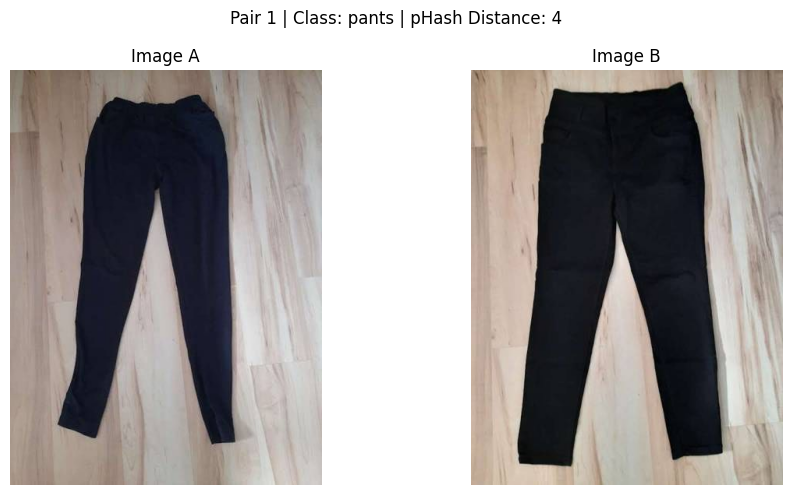

Image A: train_81c98fb1-2f1f-46aa-b60b-b330fc544c7d.jpg
Image B: train_8db4d594-4688-4447-a5b9-cd5c68b1870e.jpg
------------------------------------------------------------


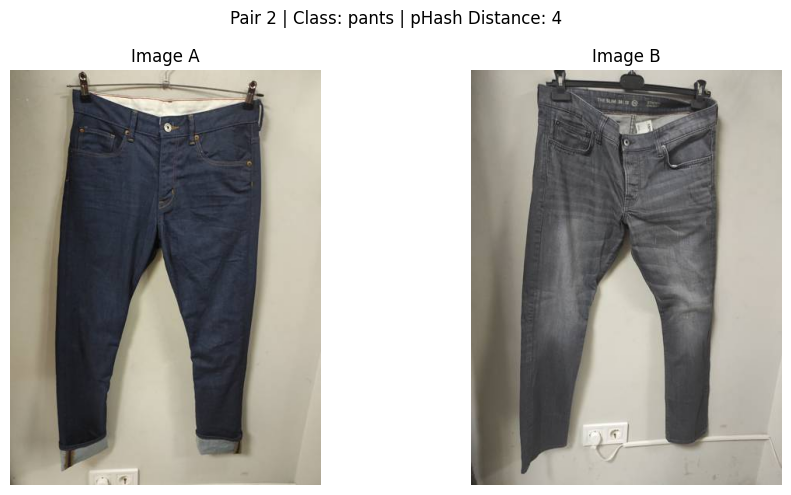

Image A: train_a88db2dc-9282-4e0f-a412-9a126b4c1b02.jpg
Image B: train_d12a6fde-d34a-4521-9752-b7a077510e41.jpg
------------------------------------------------------------


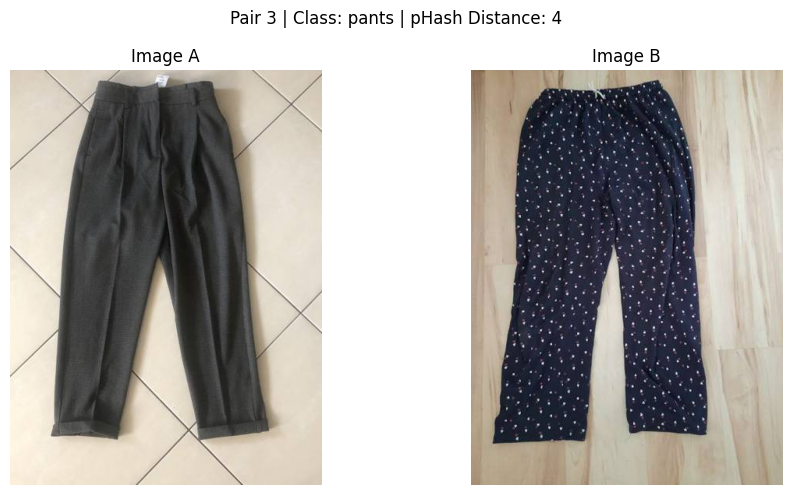

Image A: train_c9b68fc2-019a-4a4e-9709-97f75099b1e6.jpg
Image B: train_ef6d60c5-7fae-4bd8-a991-d750f0e9091a.jpg
------------------------------------------------------------


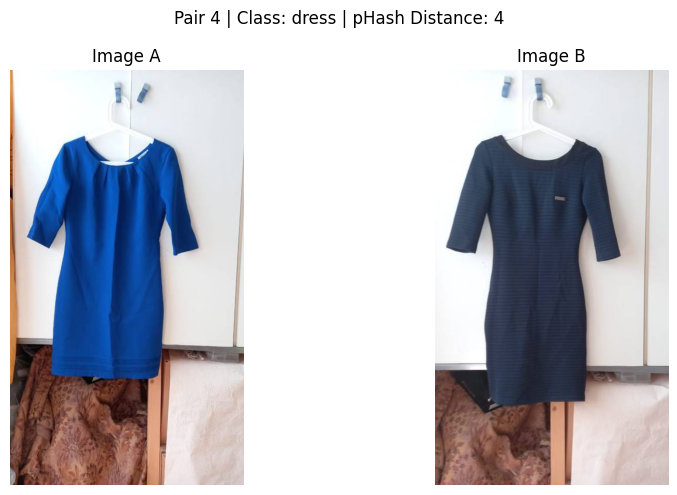

Image A: train_6e143162-9472-43c3-8db1-04eeea838ae8.jpg
Image B: train_6eaff8d0-517f-4fad-ad54-4249b8c53ff9.jpg
------------------------------------------------------------


In [ ]:

from PIL import Image
import matplotlib.pyplot as plt

# Display all potential duplicate pairs
for number, (_, row) in enumerate(
    duplicate_df.iterrows(), start=1
):

    path_1 = RAW_DIR / row["class_1"] / row["image_1"]
    path_2 = RAW_DIR / row["class_2"] / row["image_2"]

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    with Image.open(path_1) as img:
        axes[0].imshow(img.convert("RGB"))

    with Image.open(path_2) as img:
        axes[1].imshow(img.convert("RGB"))

    axes[0].set_title("Image A")
    axes[1].set_title("Image B")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"Pair {number} | "
        f"Class: {row['class_1']} | "
        f"pHash Distance: {row['hash_distance']}"
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    print("Image A:", row["image_1"])
    print("Image B:", row["image_2"])
    print("-" * 60)



### 5.1.1 Near-Duplicate Review Decisions


In [ ]:

# Record confirmed visual review decisions
duplicate_review_df = duplicate_df.copy()

assert len(duplicate_review_df) == 4, "Review the detected pairs again."

duplicate_review_df["review_decision"] = "Keep Both"

duplicate_review_df["review_reason"] = [
    "Different trouser cuts and waistband designs",
    "Different jeans colours and designs",
    "Different fabric patterns and trouser styles",
    "Different dress colours and silhouettes"
]

duplicate_review_df["confirmed_duplicate"] = False

# Save review decisions
duplicate_review_df.to_csv(
    REPORT_DIR / "duplicate_review_decisions.csv",
    index=False
)

display(duplicate_review_df)

print("Duplicate review completed!")
print("Confirmed duplicate pairs: 0")
print("Images removed: 0")


,image_1,class_1,image_2,class_2,hash_distance,duplicate_type,cross_class,review_decision,review_reason,confirmed_duplicate
0,train_81c98fb1-2f1f-46aa-b60b-b330fc544c7d.jpg,pants,train_8db4d594-4688-4447-a5b9-cd5c68b1870e.jpg,pants,4,Potential near-duplicate,False,Keep Both,Different trouser cuts and waistband designs,False
1,train_a88db2dc-9282-4e0f-a412-9a126b4c1b02.jpg,pants,train_d12a6fde-d34a-4521-9752-b7a077510e41.jpg,pants,4,Potential near-duplicate,False,Keep Both,Different jeans colours and designs,False
2,train_c9b68fc2-019a-4a4e-9709-97f75099b1e6.jpg,pants,train_ef6d60c5-7fae-4bd8-a991-d750f0e9091a.jpg,pants,4,Potential near-duplicate,False,Keep Both,Different fabric patterns and trouser styles,False
3,train_6e143162-9472-43c3-8db1-04eeea838ae8.jpg,dress,train_6eaff8d0-517f-4fad-ad54-4249b8c53ff9.jpg,dress,4,Potential near-duplicate,False,Keep Both,Different dress colours and silhouettes,False


Duplicate review completed!
Confirmed duplicate pairs: 0
Images removed: 0



### 5.2 Clothing Class Selection Criteria

Images are selected according to the following visual characteristics:

| Class | Acceptance Criteria |
|---|---|
| T-Shirt | Clearly identifiable casual T-shirt |
| Pants | Clearly identifiable full-length trousers or jeans |
| Dress | One-piece garment covering the upper body and extending into a skirt section |
| Shorts | Clearly identifiable short-length trousers |
| Outwear | Recognizable jacket, coat, or outer-layer garment |

Incorrectly labeled and visually ambiguous images are excluded or marked for further review.

Dataset quality is prioritized over image quantity.

### 5.3 Interactive Visual Label Verification

An interactive image reviewer is used to record human decisions for each candidate image.

Review decisions are automatically saved without modifying the original raw dataset.


In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
from IPython.display import display, clear_output
import pandas as pd
import ipywidgets as widgets

# ==========================================
# Configuration
# ==========================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SAIA2113_Clothing_Types_V2"
)

RAW_DIR = PROJECT_ROOT / "raw_dataset"
REPORT_DIR = PROJECT_ROOT / "reports"

REVIEW_PATH = REPORT_DIR / "visual_review_decisions.csv"

CLASSES = ["dress", "shorts", "t-shirt", "pants", "outwear"]
TARGET = 120
SEED = 42

CRITERIA = {
    "dress": "Clear one-piece dress, not a blouse or skirt.",
    "shorts": "Clearly identifiable short-length trousers.",
    "t-shirt": "Clearly identifiable casual T-shirt.",
    "pants": "Clearly identifiable full-length trousers.",
    "outwear": "Clearly identifiable jacket, coat or outer layer."
}

# ==========================================
# Load image records and existing decisions
# ==========================================

quality = pd.read_csv(
    REPORT_DIR / "image_quality_report.csv"
)

data = quality.loc[
    quality["quality_status"] == "PASS",
    ["filename", "class", "relative_path"]
].copy()

data = data.set_index("relative_path", verify_integrity=True)

data["decision"] = "PENDING"
data["reason"] = ""

if REVIEW_PATH.exists():

    saved = pd.read_csv(
        REVIEW_PATH,
        keep_default_na=False
    ).set_index("relative_path", verify_integrity=True)

    if set(saved.index) != set(data.index):
        raise ValueError(
            "Dataset has changed. Check the saved review file."
        )

    data["decision"] = saved["decision"].reindex(data.index)
    data["reason"] = saved["reason"].reindex(data.index)

    print("Previous review progress restored.")

else:
    print("Starting a new visual review.")

def save_progress():
    temporary = REVIEW_PATH.with_suffix(".tmp")
    data.to_csv(temporary)
    temporary.replace(REVIEW_PATH)

save_progress()

# ==========================================
# Interface controls
# ==========================================

class_selector = widgets.Dropdown(
    options=CLASSES,
    description="Class:",
    value="dress"
)

filter_selector = widgets.Dropdown(
    options=[
        ("Pending images", "PENDING"),
        ("Review later", "REVIEW"),
        ("All images", "ALL")
    ],
    description="Filter:"
)

reason_input = widgets.Textarea(
    placeholder="Reason for rejection or uncertainty...",
    description="Reason:",
    layout=widgets.Layout(width="95%", height="65px")
)

keep_button = widgets.Button(
    description="Keep",
    button_style="success",
    icon="check"
)

reject_button = widgets.Button(
    description="Reject",
    button_style="danger",
    icon="times"
)

review_button = widgets.Button(
    description="Review Later",
    button_style="warning"
)

previous_button = widgets.Button(description="Previous")
next_button = widgets.Button(description="Next")
undo_button = widgets.Button(description="Undo Last")

output = widgets.Output()
message = widgets.Label()

state = {"position": 0, "queue": []}
history = []

# ==========================================
# Image preview and progress
# ==========================================

def render():

    label = class_selector.value

    class_data = data[data["class"] == label]

    counts = class_data["decision"].value_counts()

    with output:
        clear_output(wait=True)

        print(f"CLASS: {label.upper()}")
        print("Criteria:", CRITERIA[label])
        print("-" * 50)

        print("Accepted:", counts.get("KEEP", 0), "/", TARGET)
        print("Rejected:", counts.get("REJECT", 0))
        print("Review later:", counts.get("REVIEW", 0))
        print("Pending:", counts.get("PENDING", 0))

        queue = state["queue"]

        if not queue:
            reason_input.value = ""
            print("\nNo images in this filter.")
            return

        position = state["position"]
        key = queue[position]
        row = data.loc[key]

        print("-" * 50)
        print(f"Image {position + 1} of {len(queue)}")
        print("Filename:", row["filename"])
        print("Current decision:", row["decision"])

        with Image.open(RAW_DIR / key) as img:
            preview = ImageOps.exif_transpose(img)
            preview = preview.convert("RGB")
            preview.thumbnail((450, 450))
            display(preview)

        reason_input.value = row["reason"]

def refresh(reset=True):

    subset = data[
        data["class"] == class_selector.value
    ].sort_index()

    subset = subset.sample(
        frac=1,
        random_state=SEED
    )

    if filter_selector.value != "ALL":
        subset = subset[
            subset["decision"] == filter_selector.value
        ]

    state["queue"] = subset.index.tolist()

    if reset:
        state["position"] = 0
    else:
        state["position"] = min(
            state["position"],
            max(0, len(state["queue"]) - 1)
        )

    render()

# ==========================================
# Review decisions
# ==========================================

def record_decision(decision):

    if not state["queue"]:
        return

    key = state["queue"][state["position"]]

    reason = reason_input.value.strip()

    if decision == "REJECT" and not reason:
        message.value = "Please enter a rejection reason."
        return

    history.append((
        key,
        data.at[key, "decision"],
        data.at[key, "reason"]
    ))

    data.at[key, "decision"] = decision
    data.at[key, "reason"] = reason

    save_progress()

    message.value = f"{decision} — Decision saved successfully."

    if filter_selector.value == "ALL":
        state["position"] += 1

    refresh(reset=False)

def navigate(direction):

    if not state["queue"]:
        return

    state["position"] = max(
        0,
        min(
            state["position"] + direction,
            len(state["queue"]) - 1
        )
    )

    render()

def undo_last():

    if not history:
        message.value = "No decision to undo in this session."
        return

    key, old_decision, old_reason = history.pop()

    data.at[key, "decision"] = old_decision
    data.at[key, "reason"] = old_reason

    save_progress()

    class_selector.value = data.at[key, "class"]
    filter_selector.value = "ALL"

    refresh()

    state["position"] = state["queue"].index(key)

    message.value = "Previous decision restored."
    render()

# ==========================================
# Connect buttons and display reviewer
# ==========================================

keep_button.on_click(
    lambda _: record_decision("KEEP")
)

reject_button.on_click(
    lambda _: record_decision("REJECT")
)

review_button.on_click(
    lambda _: record_decision("REVIEW")
)

previous_button.on_click(lambda _: navigate(-1))
next_button.on_click(lambda _: navigate(1))
undo_button.on_click(lambda _: undo_last())

class_selector.observe(
    lambda _: refresh(),
    names="value"
)

filter_selector.observe(
    lambda _: refresh(),
    names="value"
)

display(widgets.VBox([
    widgets.HTML("<h2>Clothing Dataset Reviewer</h2>"),
    widgets.HBox([class_selector, filter_selector]),
    output,
    reason_input,
    widgets.HBox([
        keep_button,
        reject_button,
        review_button
    ]),
    widgets.HBox([
        previous_button,
        next_button,
        undo_button
    ]),
    message
]))

refresh()


Starting a new visual review.



### 5.4 AI-Assisted Label Screening

A pretrained CLIP model is used to compare clothing
images against their original labels and alternative
clothing categories.

The model provides preliminary label suggestions
to assist human verification.

Existing manual review decisions are preserved.
No images are automatically deleted or approved.


In [ ]:

!pip -q install transformers


In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
from transformers import CLIPModel, AutoProcessor
from tqdm.auto import tqdm

import torch
import pandas as pd

# Configuration
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SAIA2113_Clothing_Types_V2"
)

RAW_DIR = PROJECT_ROOT / "raw_dataset"
REPORT_DIR = PROJECT_ROOT / "reports"

REVIEW_PATH = REPORT_DIR / "visual_review_decisions.csv"
SCREENING_PATH = REPORT_DIR / "ai_label_screening.csv"

CLASSES = ["dress", "shorts", "t-shirt", "pants", "outwear"]

TARGET = 120
BATCH_SIZE = 16

# Load existing human decisions
review_df = pd.read_csv(
    REVIEW_PATH,
    keep_default_na=False
)

# Display existing progress
print("CURRENT REVIEW PROGRESS")

display(pd.crosstab(
    review_df["class"],
    review_df["decision"]
))

# Preserve classes with existing manual decisions
completed_classes = [
    label for label in CLASSES
    if (
        (review_df["class"] == label) &
        (review_df["decision"] == "KEEP")
    ).any()
]

# Change this list manually if a class is
# partially reviewed rather than completed
REVIEW_CLASSES = [
    label for label in CLASSES
    if label not in completed_classes
]

print("Classes excluded:", completed_classes)
print("Classes to screen:", REVIEW_CLASSES)

# Clothing descriptions and alternative categories
PROMPTS = {
    "dress": "a photo of a one-piece dress with a skirt section",
    "shorts": "a photo of short trousers ending around or above the knee",
    "t-shirt": "a photo of a casual T-shirt",
    "pants": "a photo of full-length trousers or jeans",
    "outwear": "a photo of an outerwear jacket or coat",
    "blouse": "a photo of a blouse",
    "shirt": "a photo of a button-up shirt",
    "skirt": "a photo of a separate skirt",
    "tunic": "a photo of a long tunic top",
    "tank-top": "a photo of a sleeveless tank top",
    "capri": "a photo of cropped capri trousers",
    "leggings": "a photo of leggings",
    "sweater": "a photo of a knitted sweater",
    "other": "a photo of another type of garment"
}

# Load pretrained model
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(
    MODEL_NAME
).to(DEVICE)

processor = AutoProcessor.from_pretrained(
    MODEL_NAME
)

model.eval()

print("Running on:", DEVICE)

# Only screen unfinished candidates
candidates = review_df[
    review_df["class"].isin(REVIEW_CLASSES) &
    review_df["decision"].isin(["PENDING", "REVIEW"])
].copy()

labels = list(PROMPTS.keys())
results = []

# Process images in batches
for start in tqdm(
    range(0, len(candidates), BATCH_SIZE),
    desc="AI Label Screening"
):

    batch = candidates.iloc[start:start + BATCH_SIZE]

    images = []

    for _, row in batch.iterrows():
        with Image.open(
            RAW_DIR / row["relative_path"]
        ) as img:
            images.append(
                ImageOps.exif_transpose(img).convert("RGB")
            )

    inputs = processor(
        text=list(PROMPTS.values()),
        images=images,
        return_tensors="pt",
        padding=True
    ).to(DEVICE)

    with torch.inference_mode():
        outputs = model(**inputs)
        scores = outputs.logits_per_image.cpu().numpy()

    for (_, row), score in zip(batch.iterrows(), scores):

        original = row["class"]
        original_index = labels.index(original)
        best_index = int(score.argmax())

        alternative_score = max(
            score[i]
            for i in range(len(labels))
            if i != original_index
        )

        margin = float(
            score[original_index] - alternative_score
        )

        suggested = labels[best_index]

        results.append({
            "relative_path": row["relative_path"],
            "filename": row["filename"],
            "original_class": original,
            "suggested_class": suggested,
            "similarity_margin": margin,
            "ai_status": (
                "LABEL_MATCH"
                if original == suggested
                else "POSSIBLE_MISLABEL"
            )
        })

# Save screening results
screening_df = pd.DataFrame(
    results,
    columns=[
        "relative_path",
        "filename",
        "original_class",
        "suggested_class",
        "similarity_margin",
        "ai_status"
    ]
)

screening_df.to_csv(
    SCREENING_PATH,
    index=False
)

print("\nAI LABEL SCREENING COMPLETED")
print("Images screened:", len(screening_df))

display(pd.crosstab(
    screening_df["original_class"],
    screening_df["ai_status"]
))

print("Results saved:", SCREENING_PATH)
print("Human review decisions remain unchanged.")


CURRENT REVIEW PROGRESS


decision,KEEP,PENDING,REJECT
class,,,
dress,121,146,21
outwear,0,246,0
pants,0,559,0
shorts,121,108,28
t-shirt,0,928,0


Classes excluded: ['dress', 'shorts']
Classes to screen: ['t-shirt', 'pants', 'outwear']


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (10 outputs left out)

AI Label Screening:   0%|          | 0/109 [00:00<?, ?it/s]


AI LABEL SCREENING COMPLETED
Images screened: 1733


ai_status,LABEL_MATCH,POSSIBLE_MISLABEL
original_class,,
outwear,233,13
pants,259,300
t-shirt,775,153


Results saved: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/ai_label_screening.csv
Human review decisions remain unchanged.



### 5.5 Batch Visual Label Verification

AI-assisted screening results are used to prioritize
candidate images for human verification.

Images are displayed in batches to improve
the efficiency of manual inspection.

Human-approved images are marked as KEEP,
while questionable images are flagged for further review.

Existing manual review decisions are preserved.


In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
from IPython.display import display, clear_output

import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

# ==========================================
# Configuration
# ==========================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SAIA2113_Clothing_Types_V2"
)

RAW_DIR = PROJECT_ROOT / "raw_dataset"
REPORT_DIR = PROJECT_ROOT / "reports"

REVIEW_PATH = REPORT_DIR / "visual_review_decisions.csv"
SCREENING_PATH = REPORT_DIR / "ai_label_screening.csv"

TARGET = 120
BATCH_SIZE = 20
SEED = 42

# Load AI screening results
screening = pd.read_csv(SCREENING_PATH)

# ==========================================
# Interface controls
# ==========================================

class_selector = widgets.Dropdown(
    options=["t-shirt", "pants", "outwear"],
    description="Class:"
)

source_selector = widgets.Dropdown(
    options=[
        ("AI-matched candidates", "LABEL_MATCH"),
        ("Possible mislabels", "POSSIBLE_MISLABEL"),
        ("All pending images", "ALL")
    ],
    description="Source:"
)

approve_button = widgets.Button(
    description="Approve Batch",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="200px")
)

output = widgets.Output()
checkbox_area = widgets.VBox()
message = widgets.Label()

state = {
    "batch": [],
    "checkboxes": []
}

# ==========================================
# Load current review progress
# ==========================================

def load_review():
    return pd.read_csv(
        REVIEW_PATH,
        keep_default_na=False
    ).set_index(
        "relative_path",
        verify_integrity=True
    )

# ==========================================
# Display batch of candidate images
# ==========================================

def show_batch():

    review = load_review()
    label = class_selector.value

    class_data = review[review["class"] == label]

    accepted = int(
        (class_data["decision"] == "KEEP").sum()
    )

    remaining = max(0, TARGET - accepted)

    candidates = class_data[
        class_data["decision"] == "PENDING"
    ].reset_index()

    candidates = candidates.merge(
        screening[
            ["relative_path", "ai_status",
             "similarity_margin"]
        ],
        on="relative_path",
        how="inner",
        validate="one_to_one"
    )

    if source_selector.value != "ALL":

        candidates = candidates[
            candidates["ai_status"] ==
            source_selector.value
        ]

    # Randomized order for image diversity
    candidates = candidates.sort_values(
        "relative_path"
    ).sample(
        frac=1,
        random_state=SEED
    )

    batch = candidates.head(
        min(BATCH_SIZE, remaining)
    )

    state["batch"] = batch[
        "relative_path"
    ].tolist()

    state["checkboxes"] = []

    checkbox_area.children = ()

    approve_button.disabled = batch.empty

    with output:

        clear_output(wait=True)

        print("CLASS:", label.upper())
        print("Accepted:", accepted, "/", TARGET)
        print("Remaining to target:", remaining)
        print("Available candidates:", len(candidates))

        if remaining == 0:
            print("\nTarget reached!")
            return

        if batch.empty:
            print("\nNo candidates in this filter.")
            return

        fig, axes = plt.subplots(
            4, 5,
            figsize=(17, 13)
        )

        for ax in axes.flat:
            ax.axis("off")

        for i, (_, row) in enumerate(
            batch.iterrows()
        ):

            path = RAW_DIR / row["relative_path"]

            with Image.open(path) as img:

                preview = ImageOps.exif_transpose(
                    img
                ).convert("RGB")

                axes.flat[i].imshow(preview)

            axes.flat[i].set_title(
                f"Image {i + 1}",
                fontsize=12
            )

            checkbox = widgets.Checkbox(
                value=False,
                description=f"Image {i + 1}",
                indent=False,
                layout=widgets.Layout(width="130px")
            )

            state["checkboxes"].append(checkbox)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

    # Arrange checkboxes in rows
    checkbox_area.children = tuple(
        widgets.HBox(
            state["checkboxes"][i:i + 5]
        )
        for i in range(
            0, len(state["checkboxes"]), 5
        )
    )

# ==========================================
# Save human verification decisions
# ==========================================

def approve_batch(_):

    if not state["batch"]:
        return

    review = load_review()

    # Prevent overwriting existing decisions
    if any(
        review.at[key, "decision"] != "PENDING"
        for key in state["batch"]
    ):
        message.value = (
            "Review file changed. Batch refreshed."
        )
        show_batch()
        return

    kept = 0
    flagged = 0

    for key, checkbox in zip(
        state["batch"],
        state["checkboxes"]
    ):

        if checkbox.value:

            review.at[key, "decision"] = "REVIEW"

            review.at[key, "reason"] = (
                "Flagged during human batch inspection"
            )

            flagged += 1

        else:

            review.at[key, "decision"] = "KEEP"

            review.at[key, "reason"] = (
                "Approved through human batch verification"
            )

            kept += 1

    # Save without overwriting other class decisions
    temporary = REVIEW_PATH.with_suffix(".tmp")

    review.to_csv(temporary)
    temporary.replace(REVIEW_PATH)

    message.value = (
        f"Saved: {kept} approved, "
        f"{flagged} flagged for review."
    )

    show_batch()

# ==========================================
# Display reviewer
# ==========================================

approve_button.on_click(approve_batch)

class_selector.observe(
    lambda _: show_batch(),
    names="value"
)

source_selector.observe(
    lambda _: show_batch(),
    names="value"
)

display(widgets.VBox([
    widgets.HTML(
        "<h2>Batch Clothing Dataset Reviewer</h2>"
    ),
    class_selector,
    source_selector,
    output,
    widgets.HTML(
        "<b>Tick all questionable images below.</b>"
        "<p>Approving confirms that you have inspected "
        "every displayed image.</p>"
    ),
    checkbox_area,
    approve_button,
    message
]))

show_batch()



## 6. Final Dataset Selection

### 6.1 Human Review Summary

Summarize the recorded human review decisions
for all five clothing categories.

Only human-approved images are eligible for
the final cleaned dataset.


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SAIA2113_Clothing_Types_V2"
)

RAW_DIR = PROJECT_ROOT / "raw_dataset"
CLEAN_DIR = PROJECT_ROOT / "cleaned_dataset"
REPORT_DIR = PROJECT_ROOT / "reports"

CLASSES = ["t-shirt", "pants", "dress", "shorts", "outwear"]

review_df = pd.read_csv(
    REPORT_DIR / "visual_review_decisions.csv",
    keep_default_na=False
)

review_summary = pd.crosstab(
    review_df["class"],
    review_df["decision"]
).reindex(
    index=CLASSES,
    columns=["KEEP", "REJECT", "REVIEW", "PENDING"],
    fill_value=0
)

display(review_summary)

print("Total approved images:", review_summary["KEEP"].sum())

print("\nMinimum requirement check:")

for label in CLASSES:
    count = review_summary.loc[label, "KEEP"]
    status = "PASS" if count >= 50 else "INSUFFICIENT"
    print(f"{label}: {count} approved images - {status}")


decision,KEEP,REJECT,REVIEW,PENDING
class,,,,
t-shirt,120,0,45,763
pants,120,0,4,435
dress,121,21,0,146
shorts,121,28,0,108
outwear,120,0,8,118


Total approved images: 602

Minimum requirement check:
t-shirt: 120 approved images - PASS
pants: 120 approved images - PASS
dress: 121 approved images - PASS
shorts: 121 approved images - PASS
outwear: 120 approved images - PASS



### 6.2 Final Cleaned Dataset Creation

Select up to 120 human-approved images per class
using a fixed random seed.

Rejected, pending, and uncertain images are
excluded from the final selection.

The selected images are copied into a separate
cleaned dataset directory while preserving the
original raw dataset.


In [ ]:

import shutil
import hashlib
import pandas as pd

TARGET = 120
MIN_IMAGES = 50
SEED = 42

# Load human-approved images
approved_df = review_df[
    review_df["decision"] == "KEEP"
].copy()

selected_batches = []

# Select final images for each class
for label in CLASSES:

    candidates = approved_df[
        approved_df["class"] == label
    ].sort_values("relative_path")

    if len(candidates) < MIN_IMAGES:
        raise ValueError(
            f"{label} has fewer than 50 approved images."
        )

    selected = candidates.sample(
        n=min(TARGET, len(candidates)),
        random_state=SEED
    )

    selected_batches.append(selected)

final_df = pd.concat(
    selected_batches,
    ignore_index=True
)

# Verify source files and exact duplicates
hashes = []

for _, row in final_df.iterrows():

    source = RAW_DIR / row["relative_path"]

    if not source.is_file():
        raise FileNotFoundError(source)

    hashes.append(
        hashlib.sha256(source.read_bytes()).hexdigest()
    )

final_df["sha256"] = hashes

if final_df["sha256"].duplicated().any():
    raise ValueError("Duplicate images found in final selection.")

# Prevent mixing old and new cleaned datasets
expected_paths = {
    f"{row['class']}/{row['filename']}"
    for _, row in final_df.iterrows()
}

existing_paths = {
    p.relative_to(CLEAN_DIR).as_posix()
    for p in CLEAN_DIR.rglob("*")
    if p.is_file()
}

if existing_paths - expected_paths:
    raise ValueError(
        "Unexpected files exist in cleaned_dataset."
    )

# Copy approved images
for _, row in final_df.iterrows():

    source = RAW_DIR / row["relative_path"]

    destination = (
        CLEAN_DIR / row["class"] / row["filename"]
    )

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    shutil.copy2(source, destination)

# Record dataset provenance
final_df["source_url"] = (
    "https://github.com/alexeygrigorev/clothing-dataset-small"
)

final_df["license"] = "CC0-1.0"

final_df["cleaned_relative_path"] = (
    final_df["class"] + "/" + final_df["filename"]
)

# Save final dataset manifest
final_df.to_csv(
    REPORT_DIR / "cleaned_dataset_manifest.csv",
    index=False
)

# Final selection summary
print("FINAL DATASET SELECTION")
print("=" * 40)

display(
    final_df.groupby("class")
    .size()
    .reset_index(name="Selected Images")
)

print("Total selected images:", len(final_df))
print("Cleaned dataset:", CLEAN_DIR)
print("Original raw dataset preserved.")


FINAL DATASET SELECTION


,class,Selected Images
0,dress,120
1,outwear,120
2,pants,120
3,shorts,120
4,t-shirt,120


Total selected images: 600
Cleaned dataset: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/cleaned_dataset
Original raw dataset preserved.



## 7. Final Dataset Validation and Export

### 7.1 Final Dataset Validation

Validate the final cleaned dataset to ensure:

- Correct number of clothing classes
- Minimum image requirements
- Consistent class distribution
- Valid and readable image files
- No exact duplicate images
- Human-approved image labels
- Consistency between the dataset and its manifest


In [ ]:

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

import pandas as pd
import hashlib

# Configuration
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SAIA2113_Clothing_Types_V2"
)

RAW_DIR = PROJECT_ROOT / "raw_dataset"
CLEAN_DIR = PROJECT_ROOT / "cleaned_dataset"
REPORT_DIR = PROJECT_ROOT / "reports"

CLASSES = ["t-shirt", "pants", "dress", "shorts", "outwear"]

# Load final manifest and human decisions
manifest = pd.read_csv(
    REPORT_DIR / "cleaned_dataset_manifest.csv"
)

review = pd.read_csv(
    REPORT_DIR / "visual_review_decisions.csv"
).set_index("relative_path", verify_integrity=True)

validation_records = []

# Validate each selected image
for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Final validation"
):

    path = CLEAN_DIR / row["cleaned_relative_path"]

    record = {
        "filename": row["filename"],
        "class": row["class"],
        "relative_path": row["cleaned_relative_path"],
        "readable": False,
        "hash_match": False,
        "human_approved": False,
        "sha256": ""
    }

    if path.is_file():

        try:
            with Image.open(path) as img:
                img.load()

            record["readable"] = True

            image_hash = hashlib.sha256(
                path.read_bytes()
            ).hexdigest()

            record["sha256"] = image_hash
            record["hash_match"] = (
                image_hash == row["sha256"]
            )

        except Exception:
            pass

    source_key = row["relative_path"]

    if source_key in review.index:

        record["human_approved"] = (
            review.at[source_key, "decision"] == "KEEP"
            and review.at[source_key, "class"] == row["class"]
        )

    validation_records.append(record)

validation_df = pd.DataFrame(validation_records)

# Compare actual files with manifest
actual_files = {
    p.relative_to(CLEAN_DIR).as_posix()
    for p in CLEAN_DIR.rglob("*")
    if p.is_file()
}

expected_files = set(
    manifest["cleaned_relative_path"]
)

class_counts = manifest["class"].value_counts()

# Validation checks
checks = {
    "Five correct classes":
        set(class_counts.index) == set(CLASSES),

    "Minimum 50 images per class":
        all(class_counts.get(c, 0) >= 50 for c in CLASSES),

    "All images readable":
        validation_df["readable"].all(),

    "Image hashes match manifest":
        validation_df["hash_match"].all(),

    "All images human-approved":
        validation_df["human_approved"].all(),

    "No exact duplicate images":
        not validation_df["sha256"].duplicated().any(),

    "No duplicate manifest paths":
        not manifest["cleaned_relative_path"].duplicated().any(),

    "Dataset matches manifest":
        actual_files == expected_files
}

validation_summary = pd.DataFrame([
    {
        "Validation Check": name,
        "Status": "PASS" if result else "FAIL"
    }
    for name, result in checks.items()
])

# Save validation reports
validation_df.to_csv(
    REPORT_DIR / "final_image_validation.csv",
    index=False
)

validation_summary.to_csv(
    REPORT_DIR / "final_validation_summary.csv",
    index=False
)

display(validation_summary)

FINAL_VALIDATED = all(checks.values())

print("\nTotal images:", len(manifest))

if FINAL_VALIDATED:
    print("FINAL DATASET VALIDATION: PASSED")
else:
    print("FINAL DATASET VALIDATION: FAILED")
    print("Resolve the failed checks before proceeding.")


Final validation:   0%|          | 0/600 [00:00<?, ?it/s]

,Validation Check,Status
0,Five correct classes,PASS
1,Minimum 50 images per class,PASS
2,All images readable,PASS
3,Image hashes match manifest,PASS
4,All images human-approved,PASS
5,No exact duplicate images,PASS
6,No duplicate manifest paths,PASS
7,Dataset matches manifest,PASS



Total images: 600
FINAL DATASET VALIDATION: PASSED



### 7.2 Final Class Distribution

Visualize the distribution of the final cleaned
dataset across the five clothing categories.


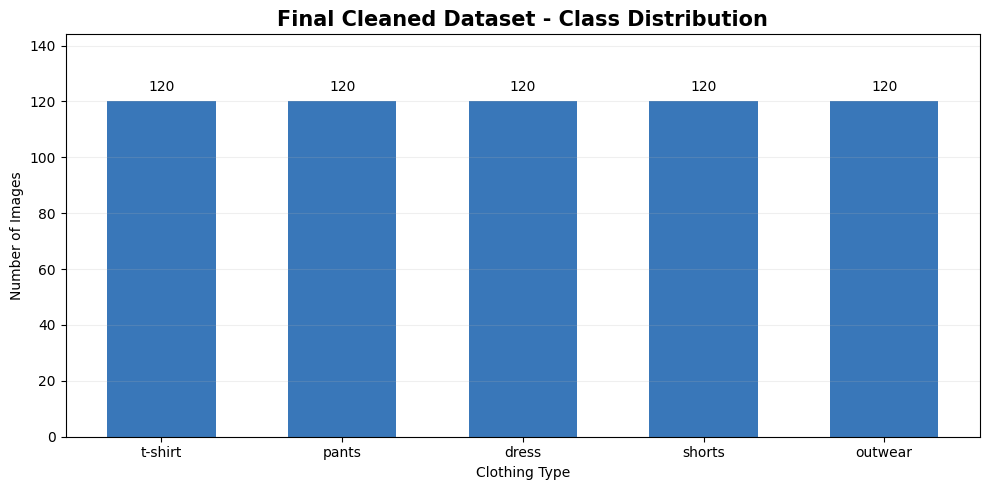

In [ ]:

import matplotlib.pyplot as plt

class_distribution = (
    manifest.groupby("class")
    .size()
    .reindex(CLASSES)
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    class_distribution.index,
    class_distribution.values,
    color="#3977b9",
    width=0.6
)

ax.bar_label(bars, padding=5)

ax.set_title(
    "Final Cleaned Dataset - Class Distribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Clothing Type")
ax.set_ylabel("Number of Images")
ax.set_ylim(0, class_distribution.max() * 1.2)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "final_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

class_distribution.rename("Images").to_csv(
    REPORT_DIR / "final_class_distribution.csv"
)



### 7.3 Final Dataset Sample Images

Display randomly selected examples from each
clothing category after data cleaning and verification.


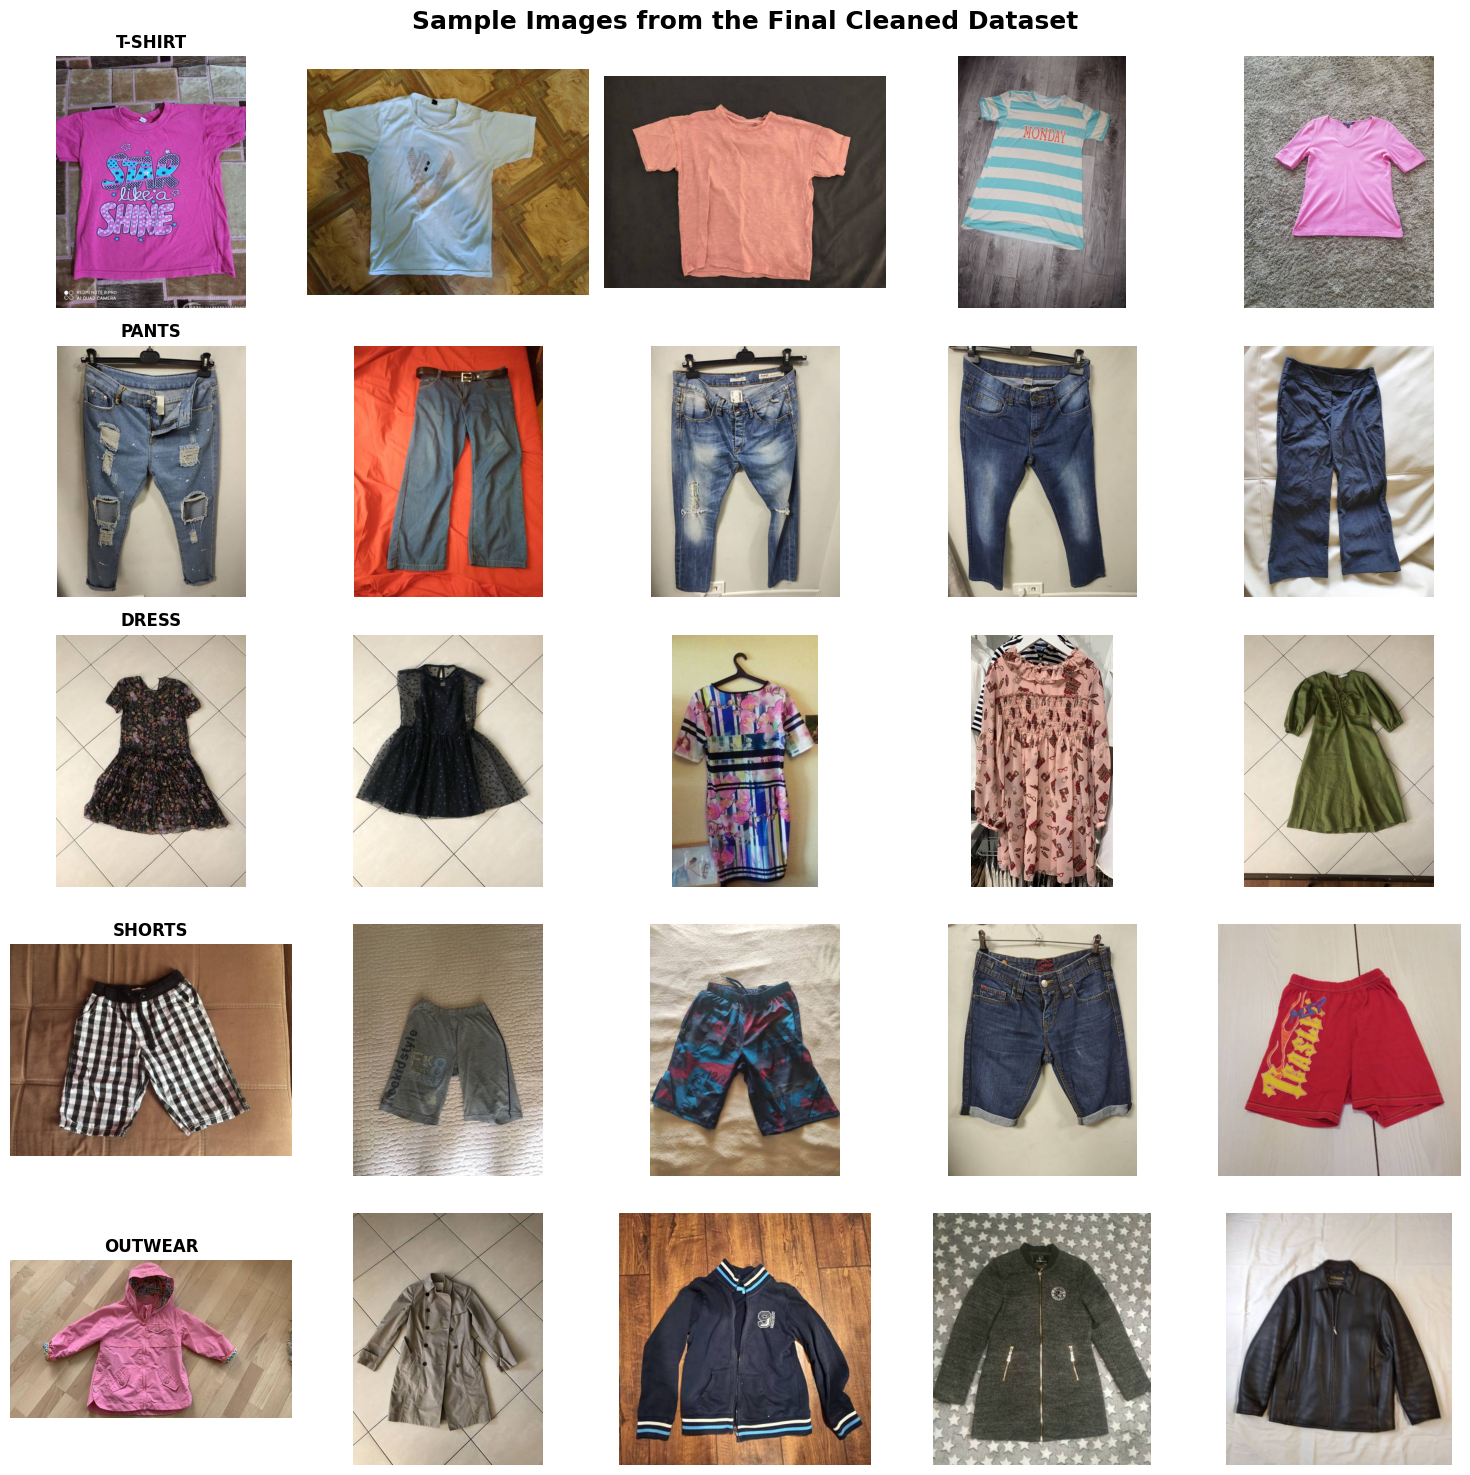

In [ ]:

from PIL import Image, ImageOps
import matplotlib.pyplot as plt

SAMPLES_PER_CLASS = 5
SEED = 42

fig, axes = plt.subplots(
    len(CLASSES),
    SAMPLES_PER_CLASS,
    figsize=(15, 15)
)

for i, label in enumerate(CLASSES):

    samples = manifest[
        manifest["class"] == label
    ].sample(
        n=SAMPLES_PER_CLASS,
        random_state=SEED
    )

    for j, (_, row) in enumerate(samples.iterrows()):

        path = CLEAN_DIR / row["cleaned_relative_path"]

        with Image.open(path) as img:

            axes[i, j].imshow(
                ImageOps.exif_transpose(img).convert("RGB")
            )

        axes[i, j].axis("off")

        if j == 0:
            axes[i, j].set_title(
                label.upper(),
                fontweight="bold"
            )

fig.suptitle(
    "Sample Images from the Final Cleaned Dataset",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "final_dataset_samples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 7.4 Final Dataset Export

Export the validated cleaned dataset and its
documentation into a ZIP archive for backup,
reproducibility, and future machine learning experiments.


In [ ]:

from zipfile import ZipFile, ZIP_DEFLATED

if not FINAL_VALIDATED:
    raise ValueError("Final dataset validation must pass first.")

ZIP_PATH = PROJECT_ROOT / "Clothing_Types_Cleaned_Dataset.zip"

with ZipFile(ZIP_PATH, "w", ZIP_DEFLATED) as archive:

    # Include cleaned dataset
    for path in sorted(CLEAN_DIR.rglob("*")):

        if path.is_file():
            archive.write(
                path,
                path.relative_to(PROJECT_ROOT)
            )

    # Include documentation and audit reports
    for path in sorted(REPORT_DIR.rglob("*")):

        if path.is_file():
            archive.write(
                path,
                path.relative_to(PROJECT_ROOT)
            )

size_mb = ZIP_PATH.stat().st_size / (1024 * 1024)

print("Dataset exported successfully!")
print("ZIP location:", ZIP_PATH)
print(f"ZIP size: {size_mb:.2f} MB")


Dataset exported successfully!
ZIP location: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/Clothing_Types_Cleaned_Dataset.zip
ZIP size: 28.88 MB



### 7.5 Reproducibility Information

Record the dataset source version, Python environment,
library versions, and random seed used during
dataset collection and cleaning.

This information supports reproducibility of the
data collection pipeline.


In [ ]:
import sys
import json
import subprocess
from importlib.metadata import version

# Record installed library versions
libraries = [
    "numpy",
    "pandas",
    "Pillow",
    "ImageHash",
    "matplotlib",
    "ipywidgets",
    "tqdm",
    "torch",
    "transformers"
]

library_versions = {
    lib: version(lib)
    for lib in libraries
}

# Save Phase 1 requirements
requirements_path = REPORT_DIR / "requirements_phase1.txt"

with open(requirements_path, "w") as f:
    for lib, ver in library_versions.items():
        f.write(f"{lib}=={ver}\n")

# Record source dataset commit
source_commit = subprocess.check_output(
    [
        "git", "-C",
        "/content/clothing-dataset-small",
        "rev-parse", "HEAD"
    ],
    text=True
).strip()

# Save project metadata
metadata = {
    "project": "Clothing Types Image Classification",
    "course": "SAIA 2113 Machine Learning",
    "dataset_source": (
        "https://github.com/alexeygrigorev/"
        "clothing-dataset-small"
    ),
    "dataset_commit": source_commit,
    "license": "CC0-1.0",
    "random_seed": 42,
    "python_version": sys.version,
    "classes": CLASSES,
    "total_images": len(manifest),
    "class_distribution": (
        manifest["class"].value_counts().to_dict()
    ),
    "minimum_images_per_class": 50,
    "preferred_images_per_class": 120,
    "minimum_resolution": 100,
    "phash_threshold": 4,
    "label_screening_model": "openai/clip-vit-base-patch32",
    "library_versions": library_versions
}

metadata_path = REPORT_DIR / "dataset_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Reproducibility information saved!")
print("Requirements:", requirements_path)
print("Metadata:", metadata_path)

display(
    pd.DataFrame(
        library_versions.items(),
        columns=["Library", "Version"]
    )
)

Reproducibility information saved!
Requirements: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/requirements_phase1.txt
Metadata: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/dataset_metadata.json


,Library,Version
0,numpy,2.4.6
1,pandas,2.2.3
2,Pillow,11.3.0
3,ImageHash,4.3.2
4,matplotlib,3.10.0
5,ipywidgets,7.7.1
6,tqdm,4.67.3
7,torch,2.14.1+cpu
8,transformers,5.22.1
